In [ ]:
import torch
from torch import nn
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
device

'cuda'

In [ ]:
from zipfile import ZipFile
from pathlib import Path

data_path = Path("data/")
image_path = data_path / "rock_paper_scissors"

if image_path.is_dir():
  print(f"{image_path} Directory exists")
else:
  print(f"Did not find {image_path} directory. Creating one...")
  image_path.mkdir(parents=True, exist_ok=True)

  with ZipFile("/content/drive/MyDrive/Deep Learning/rps-cv-images.zip", "r") as zip_ref:
    print("Unzipping rock, paper and scissors data...")
    zip_ref.extractall(image_path)


Did not find data/rock_paper_scissors directory. Creating one...
Unzipping rock, paper and scissors data...


In [ ]:
import os
def walk_through_dir(dir_path):
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f"There are {len(dirnames)} directories and {len(filenames)} images in {dirpath}")

In [ ]:
walk_through_dir(image_path / "rps-cv-images")

There are 3 directories and 1 images in data/rock_paper_scissors/rps-cv-images
There are 0 directories and 712 images in data/rock_paper_scissors/rps-cv-images/paper
There are 0 directories and 750 images in data/rock_paper_scissors/rps-cv-images/scissors
There are 0 directories and 726 images in data/rock_paper_scissors/rps-cv-images/rock


Random image path: data/rock_paper_scissors/rps-cv-images/paper/8X1BUL9w2OMExPy5.png
Image class: paper
Image height: 200
Image width: 300


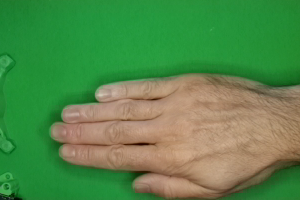

In [ ]:
import random
from PIL import Image

data_path = Path("data/")
image_path = data_path / "rock_paper_scissors"
dataset_path = image_path / "rps-cv-images"

# set seed
random.seed(42)

# Get all image paths
image_path_list = list(dataset_path.glob(r"*/*.png"))

# Get random image path
random_image_path = random.choice(image_path_list)

# Get image class from path name
image_class = random_image_path.parent.stem

# Open image
img = Image.open(random_image_path)

# Print metadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
img

(np.float64(-0.5), np.float64(299.5), np.float64(199.5), np.float64(-0.5))

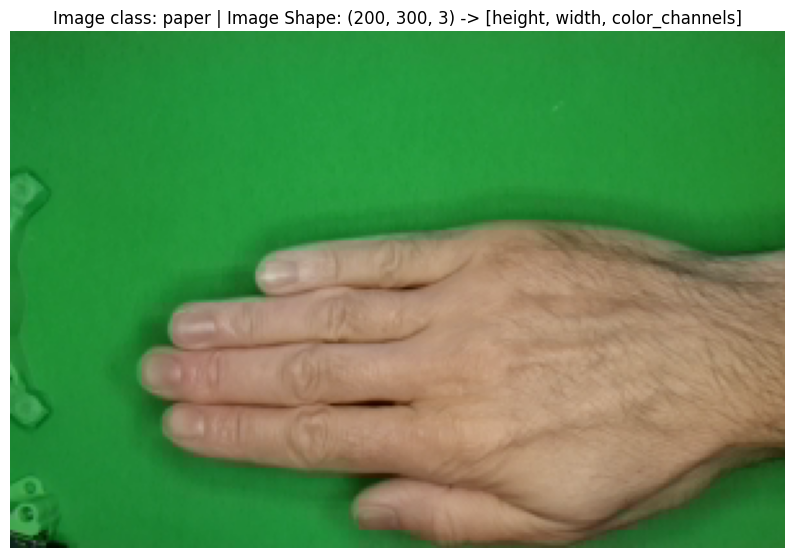

In [ ]:
# Doing the same with matplotlib
import numpy as np
import matplotlib.pyplot as plt

# Turn image into numpy array
img_as_array = np.asarray(img)

# Plot image with matplotlib
plt.figure(figsize=(10, 7))
plt.imshow(img_as_array)
plt.title(f"Image class: {image_class} | Image Shape: {img_as_array.shape} -> [height, width, color_channels]")
plt.axis(False)


In [ ]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

data_transform = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])


In [ ]:
def plot_transformed_images(image_paths, transform, n=3, seed=42):
  random.seed(seed)
  random_image_paths = random.sample(image_paths, k=n)
  for image_path in random_image_paths:
    with Image.open(image_path) as f:
      fig, ax = plt.subplots(1, 2)
      ax[0].imshow(f)
      ax[0].set_title(f"Original \nSize: {f.size}")
      ax[0].axis("off")

      # Note: permute() will change the shape of the image to suit matplotlib
      # Pytorch default is [C, H, W] but matplotlib is [H, W, C]
      transformed_image = transform(f).permute(1, 2, 0)
      ax[1].imshow(transformed_image)
      ax[1].set_title(f"Transformed \nSize: {transformed_image.shape}")
      ax[1].axis("off")

      fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)

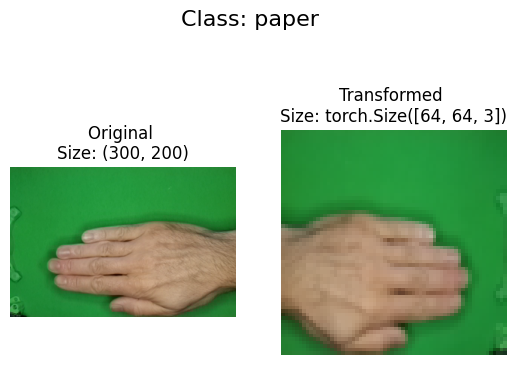

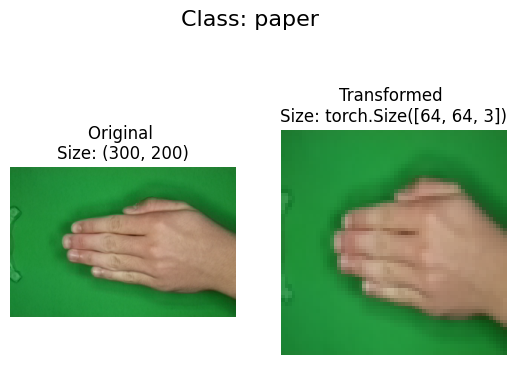

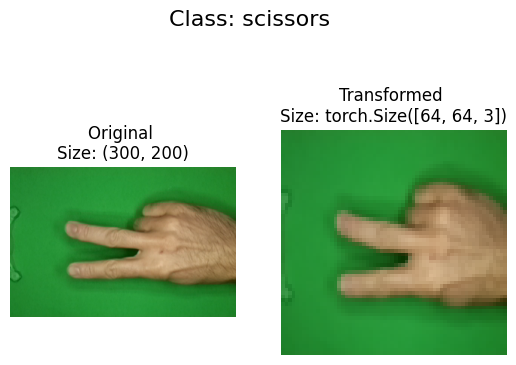

In [ ]:
plot_transformed_images(image_path_list,
                        data_transform)

In [ ]:
dataset = datasets.ImageFolder(root=dataset_path,
                         transform=data_transform,
                         target_transform=None)
# Split into train and test
train_ratio = 0.8
test_ratio = 0.2
dataset_size=len(dataset)
train_size = int(train_ratio * dataset_size)
test_size = dataset_size - train_size

train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

# Dataloader
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [ ]:
class_names = dataset.classes
class_names

['paper', 'rock', 'scissors']

In [ ]:
class_dict = dataset.class_to_idx
class_dict

{'paper': 0, 'rock': 1, 'scissors': 2}

In [ ]:
print(f"Full dataset length:{len(dataset)}")
print(f"Train dataset length:{len(train_dataset)}")
print(f"Test dataset length:{len(test_dataset)}")

Full dataset length:2188
Train dataset length:1750
Test dataset length:438


In [ ]:
img, label = train_dataset[0][0], train_dataset[0][1]
print(f"Image Tensor: \n{img}")
print(f"Image Shape: \n{img.shape}")
print(f"Image Datatype: \n{img.dtype}")
print(f"Image Label: \n{label}")
print(f"Label Datatype: \n{type(label)}")

Image Tensor: 
tensor([[[0.0980, 0.0902, 0.0980,  ..., 0.1451, 0.1412, 0.1412],
         [0.0941, 0.0902, 0.0941,  ..., 0.1412, 0.1412, 0.1451],
         [0.0902, 0.0863, 0.0902,  ..., 0.1373, 0.1373, 0.1412],
         ...,
         [0.0667, 0.0627, 0.0588,  ..., 0.1137, 0.1216, 0.1216],
         [0.0627, 0.0627, 0.0627,  ..., 0.1137, 0.1216, 0.1216],
         [0.0784, 0.0784, 0.0784,  ..., 0.1294, 0.1333, 0.1412]],

        [[0.4235, 0.4275, 0.4353,  ..., 0.5373, 0.5294, 0.5294],
         [0.4196, 0.4196, 0.4314,  ..., 0.5373, 0.5373, 0.5373],
         [0.4118, 0.4118, 0.4196,  ..., 0.5412, 0.5412, 0.5412],
         ...,
         [0.3961, 0.3961, 0.3961,  ..., 0.5333, 0.5373, 0.5333],
         [0.3961, 0.3961, 0.4000,  ..., 0.5294, 0.5333, 0.5333],
         [0.3882, 0.3961, 0.4000,  ..., 0.5255, 0.5294, 0.5333]],

        [[0.1216, 0.1255, 0.1294,  ..., 0.2196, 0.2196, 0.2157],
         [0.1216, 0.1216, 0.1255,  ..., 0.2157, 0.2196, 0.2196],
         [0.1216, 0.1176, 0.1216,  ..., 0.2

Original shape: torch.Size([3, 64, 64]) -> [color_channels, width, height]
Image permute shape: torch.Size([64, 64, 3]) -> [height, width, color_channels]


Text(0.5, 1.0, 'rock')

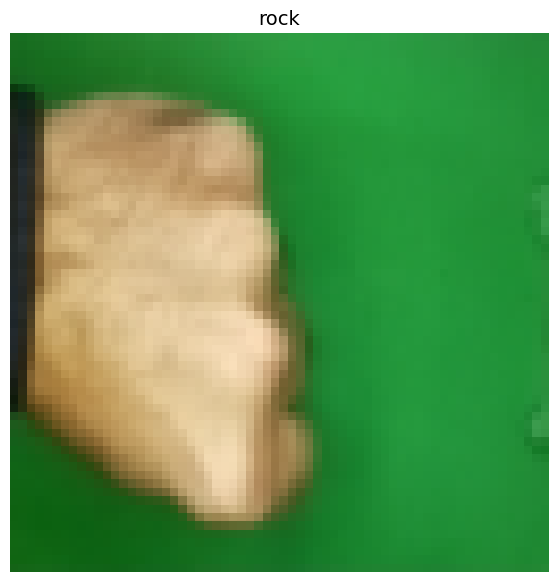

In [ ]:
img_permute = img.permute(1,2,0)

print(f"Original shape: {img.shape} -> [color_channels, width, height]")
print(f"Image permute shape: {img_permute.shape} -> [height, width, color_channels]")

plt.figure(figsize=(10, 7))
plt.imshow(img_permute)
plt.axis("off")
plt.title(class_names[label], fontsize=14)

In [ ]:
img, label = next(iter(train_dataloader))
print(f"Image shape: {img.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label.shape}")

Image shape: torch.Size([32, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([32])


In [ ]:
import torch
from torch import nn

class TinyVGG(nn.Module):
  def __init__(self, input_shape: int, hidden_units: int, output_shape: int) -> None:
    super().__init__()
    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                     stride=2)

    )

    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2) # default stride is the same as kernel_size


    )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units*16*16,
                  out_features=output_shape)
    )

  def forward(self, x: torch.Tensor):
    return(self.classifier(self.conv_block_2(self.conv_block_1(x))))

In [ ]:
torch.manual_seed(42)
model_0 = TinyVGG(input_shape=3, # number of color channels
                  hidden_units=10,
                  output_shape=len(dataset.classes)
                  ).to(device)
model_0

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

In [ ]:
# pass a single image to our model just to see
img_batch, label_batch = next(iter(train_dataloader))

# Get a single image from the batch and unsqueeze the image so its shape fits the model
img_single, label_single = img_batch[0].unsqueeze(dim=0), label_batch[0]
print(f"Single image shape: {img_single.shape}\n")

model_0.eval()
with torch.inference_mode():
  pred = model_0(img_single.to(device))

# print out what's happening and convert model logits -> pred probs -> pred label
print(f"Output logits:\n{pred}\n")
print(f"Output prediction probabilities:\n{torch.softmax(pred, dim=1)}\n")
print(f"Output prediction label:\n{torch.argmax(torch.softmax(pred, dim=1), dim=1)}\n")
print(f"Actual label:\n{label_single}")

Single image shape: torch.Size([1, 3, 64, 64])

Output logits:
tensor([[0.0617, 0.0624, 0.0384]], device='cuda:0')

Output prediction probabilities:
tensor([[0.3358, 0.3361, 0.3281]], device='cuda:0')

Output prediction label:
tensor([1], device='cuda:0')

Actual label:
1


In [ ]:
try:
  import torchinfo
except:
  !pip install torchinfo
  import torchinfo

from torchinfo import summary
summary(model_0, input_size=[32, 3, 64, 64])

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [32, 3]                   --
├─Sequential: 1-1                        [32, 10, 32, 32]          --
│    └─Conv2d: 2-1                       [32, 10, 64, 64]          280
│    └─ReLU: 2-2                         [32, 10, 64, 64]          --
│    └─Conv2d: 2-3                       [32, 10, 64, 64]          910
│    └─ReLU: 2-4                         [32, 10, 64, 64]          --
│    └─MaxPool2d: 2-5                    [32, 10, 32, 32]          --
├─Sequential: 1-2                        [32, 10, 16, 16]          --
│    └─Conv2d: 2-6                       [32, 10, 32, 32]          910
│    └─ReLU: 2-7                         [32, 10, 32, 32]          --
│    └─Conv2d: 2-8                       [32, 10, 32, 32]          910
│    └─ReLU: 2-9                         [32, 10, 32, 32]          --
│    └─MaxPool2d: 2-10                   [32, 10, 16, 16]          --
├─Sequentia

In [ ]:
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer):
  model.train()
  train_loss, train_acc = 0, 0

  for batch, (X, y) in enumerate(dataloader):
    X, y = X.to(device), y.to(device)

    y_pred = model(X)

    loss = loss_fn(y_pred, y)
    train_loss += loss.item()

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
    train_acc += (y_pred_class == y).sum().item()/len(y_pred)

  train_loss = train_loss / len(dataloader)
  train_acc = train_acc / len(dataloader)
  return train_loss, train_acc

In [ ]:
def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module):
  model.eval()

  test_loss, test_acc = 0, 0

  with torch.inference_mode():
    for batch, (X, y) in enumerate(dataloader):
      X, y = X.to(device), y.to(device)

      test_pred_logits = model(X)

      loss = loss_fn(test_pred_logits, y)
      test_loss += loss.item()

      test_pred_labels = test_pred_logits.argmax(dim=1)
      test_acc += (test_pred_labels == y).sum().item()/len(test_pred_labels)

    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc

In [ ]:
from tqdm.auto import tqdm

def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5):

  results = {"train_loss": [],
             "train_acc": [],
             "test_loss": [],
             "test_acc": []
             }

  for epoch in tqdm(range(epochs)):
    train_loss, train_acc = train_step(model=model,
                                       dataloader=train_dataloader,
                                       loss_fn=loss_fn,
                                       optimizer=optimizer)
    test_loss, test_acc = test_step(model=model,
                                    dataloader=test_dataloader,
                                    loss_fn=loss_fn)

    print(
        f"Epoch: {epoch+1} |"
        f"train_loss: {train_loss:.4f} |"
        f"train_acc: {train_acc:.4f} |"
        f"test_loss: {test_loss:.4f} |"
        f"test_acc: {test_acc:.4f} |"
    )

    results["train_loss"].append(train_loss.item() if isinstance(train_loss, torch.Tensor) else train_loss)
    results["train_acc"].append(train_acc.item() if isinstance(train_acc, torch.Tensor) else train_acc)
    results["test_loss"].append(test_loss.item() if isinstance(test_loss, torch.Tensor) else test_loss)
    results["test_acc"].append(test_acc.item() if isinstance(test_acc, torch.Tensor) else test_acc)

  return results


In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

NUM_EPOCHS = 5

model_0 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(dataset.classes)).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.001)

from timeit import default_timer as timer
start_time = timer()

model_0_results = train(model=model_0,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader,
                        loss_fn=loss_fn,
                        optimizer=optimizer,
                        epochs=NUM_EPOCHS)
end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

I had to remove the last cell's output because it used widgets and GitHub couldn't show it.
here is the output to the last cell:
Epoch: 1 |train_loss: 1.0964 |train_acc: 0.3618 |test_loss: 1.0878 |test_acc: 0.3228 |
Epoch: 2 |train_loss: 0.9843 |train_acc: 0.5042 |test_loss: 0.8644 |test_acc: 0.6938 |
Epoch: 3 |train_loss: 0.7733 |train_acc: 0.7044 |test_loss: 0.6130 |test_acc: 0.7938 |
Epoch: 4 |train_loss: 0.6100 |train_acc: 0.7754 |test_loss: 0.4537 |test_acc: 0.8486 |
Epoch: 5 |train_loss: 0.4030 |train_acc: 0.8679 |test_loss: 0.3258 |test_acc: 0.9010 |
Total training time: 32.512 seconds

#References:
[geeksforgeeks_split_data](https://www.geeksforgeeks.org/deep-learning/how-to-split-a-dataset-using-pytorch/)

[pytorch_tutorial](https://www.learnpytorch.io/04_pytorch_custom_datasets/)

[pytorch_tutorial_youtube](https://www.youtube.com/watch?v=Z_ikDlimN6A)